<a href="https://colab.research.google.com/github/SudemZeynep/adversarial-robustness-cnn-vit/blob/main/01_fgsm_pgd_cnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
from datasets import load_dataset

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

ds = load_dataset("uoft-cs/cifar10")
classes = ds["train"].features["label"].names

def to_ds(split):
    x = torch.tensor(np.stack([np.array(i) for i in ds[split]["img"]]))
    x = x.permute(0, 3, 1, 2).float() / 255
    y = torch.tensor(ds[split]["label"])
    return torch.utils.data.TensorDataset(x, y)

train, test = to_ds("train"), to_ds("test")
train_dl = torch.utils.data.DataLoader(train, batch_size=128, shuffle=True)
test_dl = torch.utils.data.DataLoader(test, batch_size=256)
print("hazır")

cuda


README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

hazır


In [2]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.c1 = nn.Conv2d(3, 32, 3, padding=1)
        self.c2 = nn.Conv2d(32, 64, 3, padding=1)
        self.c3 = nn.Conv2d(64, 128, 3, padding=1)
        self.fc = nn.Linear(128 * 4 * 4, 10)
    def forward(self, x):
        x = F.max_pool2d(F.relu(self.c1(x)), 2)
        x = F.max_pool2d(F.relu(self.c2(x)), 2)
        x = F.max_pool2d(F.relu(self.c3(x)), 2)
        return self.fc(x.flatten(1))

model = Net().to(device)
opt = torch.optim.Adam(model.parameters(), 1e-3)

for epoch in range(8):
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        loss = F.cross_entropy(model(x), y)
        opt.zero_grad(); loss.backward(); opt.step()
    print("epoch", epoch + 1, "bitti")

epoch 1 bitti
epoch 2 bitti
epoch 3 bitti
epoch 4 bitti
epoch 5 bitti
epoch 6 bitti
epoch 7 bitti
epoch 8 bitti


In [3]:
def fgsm(model, x, y, eps):
    x = x.clone().requires_grad_(True)
    loss = F.cross_entropy(model(x), y)
    loss.backward()
    x_adv = x + eps * x.grad.sign()   # hatayı artıran yöne tek adım x.grad.sign()
    return x_adv.clamp(0, 1).detach()

def accuracy(eps):
    model.eval() #Modeli “sınav moduna” al, artık öğrenmiyor.
    correct = 0
    for x, y in test_dl:
        x, y = x.to(device), y.to(device)
        if eps > 0:
            x = fgsm(model, x, y, eps)
        correct += (model(x).argmax(1) == y).sum().item()
    return correct / len(test)

for e in [0, 1/255, 2/255, 4/255, 8/255]:
    print(f"eps={e*255:.0f}/255  doğruluk={accuracy(e):.3f}")

eps=0/255  doğruluk=0.724
eps=1/255  doğruluk=0.543
eps=2/255  doğruluk=0.380
eps=4/255  doğruluk=0.169
eps=8/255  doğruluk=0.029


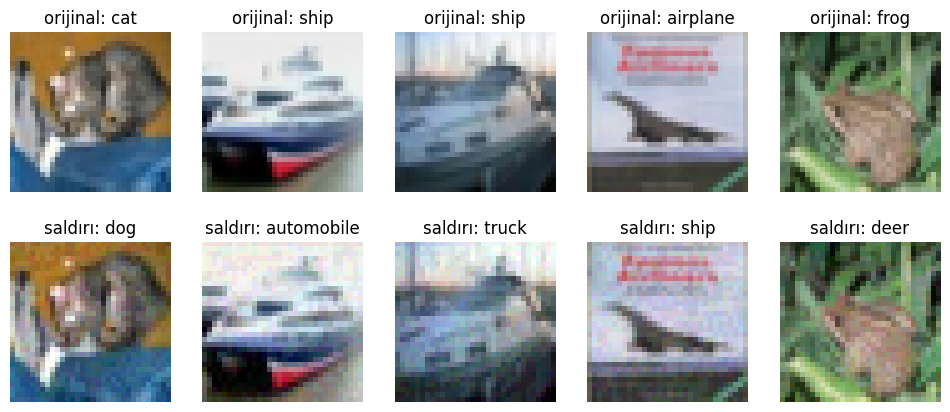

In [4]:
x, y = next(iter(test_dl))
x, y = x[:5].to(device), y[:5].to(device)
x_adv = fgsm(model, x, y, 8/255)
p, pa = model(x).argmax(1), model(x_adv).argmax(1)

fig, ax = plt.subplots(2, 5, figsize=(12, 5))
for i in range(5):
    ax[0, i].imshow(x[i].cpu().permute(1, 2, 0)); ax[0, i].set_title(f"orijinal: {classes[p[i]]}"); ax[0, i].axis("off")
    ax[1, i].imshow(x_adv[i].cpu().permute(1, 2, 0)); ax[1, i].set_title(f"saldırı: {classes[pa[i]]}"); ax[1, i].axis("off")
plt.show()

In [5]:
def pgd(model, x, y, eps, alpha=2/255, steps=10):
    # rastgele bir noktadan başla (ε sınırının içinde)
    x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1).detach()
    for _ in range(steps):
        x_adv.requires_grad_(True)
        loss = F.cross_entropy(model(x_adv), y)
        grad = torch.autograd.grad(loss, x_adv)[0]
        x_adv = x_adv.detach() + alpha * grad.sign()               # küçük adım
        x_adv = torch.min(torch.max(x_adv, x - eps), x + eps)      # ε çitinin içine geri çek
        x_adv = x_adv.clamp(0, 1)                                   # geçerli piksel aralığı
    return x_adv.detach()

def acc_attack(attack, eps):
    model.eval(); correct = 0
    for x, y in test_dl:
        x, y = x.to(device), y.to(device)
        if eps > 0:
            x = attack(model, x, y, eps)
        with torch.no_grad():
            correct += (model(x).argmax(1) == y).sum().item()
    return correct / len(test)

print("FGSM eps=8/255:", acc_attack(fgsm, 8/255))
print("PGD  eps=8/255:", acc_attack(pgd, 8/255))

FGSM eps=8/255: 0.0293
PGD  eps=8/255: 0.0038


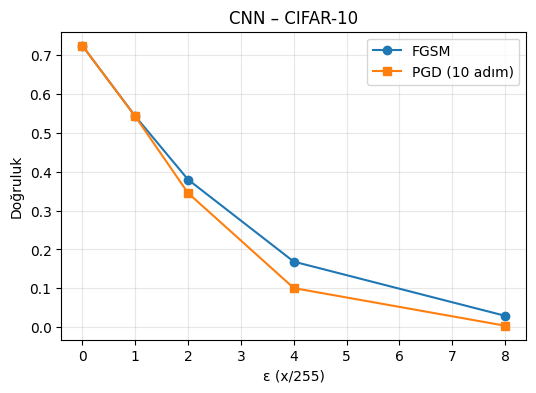

ε=0/255  FGSM=0.724  PGD=0.724
ε=1/255  FGSM=0.543  PGD=0.542
ε=2/255  FGSM=0.380  PGD=0.345
ε=4/255  FGSM=0.169  PGD=0.101
ε=8/255  FGSM=0.029  PGD=0.004


In [6]:
eps_list = [0, 1, 2, 4, 8]
fgsm_acc = [acc_attack(fgsm, e/255) for e in eps_list]
pgd_acc  = [acc_attack(pgd,  e/255) for e in eps_list]

plt.figure(figsize=(6, 4))
plt.plot(eps_list, fgsm_acc, "o-", label="FGSM")
plt.plot(eps_list, pgd_acc,  "s-", label="PGD (10 adım)")
plt.xlabel("ε (x/255)"); plt.ylabel("Doğruluk"); plt.title("CNN – CIFAR-10")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig("eps_egrisi.png", dpi=150); plt.show()

for e, f, p in zip(eps_list, fgsm_acc, pgd_acc):
    print(f"ε={e}/255  FGSM={f:.3f}  PGD={p:.3f}")